<a href="https://colab.research.google.com/github/mrdantzig/nlp-bible-code/blob/master/13%EC%9E%A5_%EC%9E%90%EC%97%B0%EC%96%B4%EC%83%9D%EC%84%B1/%5B13-1-%EC%88%98%EC%A0%95%5DLSTM%20%EB%84%A4%ED%8A%B8%EC%9B%8C%ED%81%AC%EB%A5%BC%20%EC%9D%B4%EC%9A%A9%ED%95%9C%20%EC%9E%90%EC%97%B0%EC%96%B4%20%EC%83%9D%EC%84%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from __future__ import print_function
from tensorflow.keras.callbacks import LambdaCallback
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.utils import get_file
import numpy as np
import random
import sys
import io

In [2]:
# 텍스트 파일 불러오기
fpath = get_file(
    'nietzsche.txt',
    origin='https://s3.amazonaws.com/text-datasets/nietzsche.txt')
with io.open(fpath, encoding='utf-8') as f:
    text = f.read().lower()

# 어휘 사전 생성
chars = sorted(list(set(text)))
char2index = dict((c, i) for i, c in enumerate(chars))
index2char = dict((i, c) for i, c in enumerate(chars))

# 음절 단위 학습 데이터 생성
maxlen, step = 40, 3
sentences, next_chars = [], []
for i in range(0, len(text) - maxlen, step):
    sentences.append(text[i : i + maxlen])
    next_chars.append(text[i + maxlen])
print ('The number of sentences:', len(sentences))
x = np.zeros((len(sentences), maxlen, len(chars)), dtype=np.bool)
y = np.zeros((len(sentences), len(chars)), dtype=np.bool)

for i, sentence in enumerate(sentences):
    for t, char in enumerate(sentence):
        x[i, t, char2index[char]] = 1
    y[i, char2index[next_chars[i]]] = 1

600901/600901 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
The number of sentences: 200285


In [4]:
# ===== 수업용 실행 설정 (시간이 부족하면 이 값만 조정) =====
EPOCHS = 5                  # 원본 60 → 5
GEN_LEN = 100               # epoch마다 생성할 글자 수 (원본 400)
DIVERSITIES = [0.2, 1.2]    # 비교할 온도 (원본 0.2, 0.5, 1.0, 1.2) - 차이가 가장 큰 두 값만
GEN_EVERY = 1               # 몇 epoch마다 생성할지 (2로 바꾸면 생성 횟수가 절반)

# 딥러닝 모델 선언
model = Sequential()
model.add(LSTM(128, input_shape=(maxlen, len(chars))))
model.add(Dense(len(chars), activation='softmax'))
optimizer = RMSprop(learning_rate=0.01)
model.compile(loss='categorical_crossentropy', optimizer=optimizer)

# 입력된 확률값에 따른 다음 음절 샘플링 (원본과 동일)
def sample(preds, temperature=1.0):
    preds = np.asarray(preds).astype('float64')
    preds = np.log(preds) / temperature
    exp_preds = np.exp(preds)
    preds = exp_preds / np.sum(exp_preds)
    probas = np.random.multinomial(1, preds, 1)
    return np.argmax(probas)

# 매 epoch 종료 시 텍스트 생성
def on_epoch_end(epoch, _):
    if (epoch + 1) % GEN_EVERY != 0:
        return
    print('\n===== Epoch: %d =====' % (epoch + 1))
    start_index = random.randint(0, len(text) - maxlen - 1)
    for diversity in DIVERSITIES:
        print('\nDiversity:', diversity)
        sentence = text[start_index : start_index + maxlen]
        print('Seed: %s' % sentence)
        sys.stdout.write(sentence)
        for i in range(GEN_LEN):
            x_pred = np.zeros((1, maxlen, len(chars)))
            for t, char in enumerate(sentence):
                x_pred[0, t, char2index[char]] = 1.
            # predict() 대신 직접 호출: 결과는 같고 한 건씩 호출할 때 훨씬 빠름
            preds = model(x_pred, training=False).numpy()[0]
            next_index = sample(preds, diversity)
            next_char = index2char[next_index]
            sentence = sentence[1:] + next_char
            sys.stdout.write(next_char)
            sys.stdout.flush()
        print()

print_callback = LambdaCallback(on_epoch_end=on_epoch_end)
model.fit(x, y,
          batch_size=128,
          epochs=EPOCHS,
          callbacks=[print_callback])

Epoch 1/5
1565/1565 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2.3202
===== Epoch: 1 =====

Diversity: 0.2
Seed: tly
breaking down, and a future over-you
tly
breaking down, and a future over-you hand and his ord and the man and and into the strengure and and his not the sense, and and and the 

Diversity: 1.2
Seed: tly
breaking down, and a future over-you
tly
breaking down, and a future over-you suffaraycevn), a btly the palortesible, "more.
sy go we his yes to think, man our who"mehish"y that
1565/1565 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - loss: 2.0247
Epoch 2/5
1558/1565 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.6738
===== Epoch: 2 =====

Diversity: 0.2
Seed:  of unholiness simply a healthful and ho
 of unholiness simply a healthful and how the more present and which deverents to the earth and the self and and the precession of the sense

Diversity: 1.2
Seed:  of unholiness simply a healthful and ho
 of unholiness simply a healthful and homary theresens, would, an them his is as hard mo

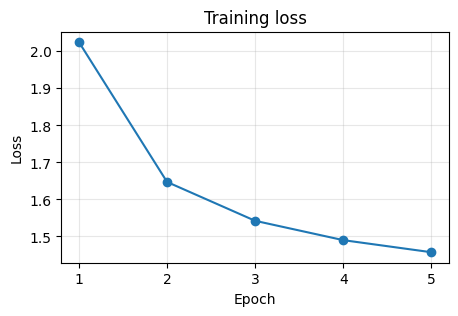

Seed: 'ndered harmless? why should we\nstill pun' | top-1 prob = 0.33


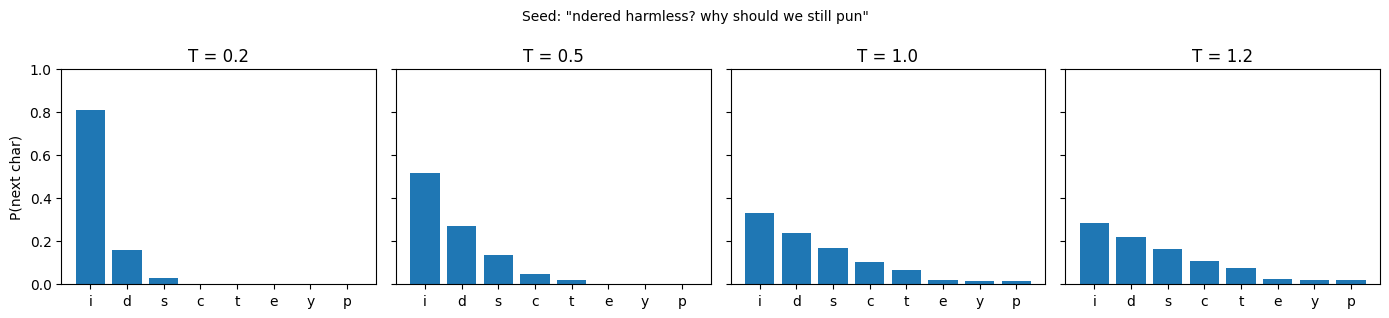

In [9]:
import matplotlib.pyplot as plt

# 마지막 fit()의 학습 기록 가져오기
history = model.history

# ----- 1) epoch별 학습 손실 -----
loss = history.history['loss']
plt.figure(figsize=(5, 3))
plt.plot(range(1, len(loss) + 1), loss, marker='o')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Training loss')
plt.xticks(range(1, len(loss) + 1))
plt.grid(alpha=0.3)
plt.show()

# ----- 2) 실제 모델의 다음 문자 확률: 온도별 비교 -----
def apply_temperature(p, T):
    q = np.exp(np.log(p) / T)
    return q / q.sum()

def next_char_probs(seed):
    x_pred = np.zeros((1, maxlen, len(chars)))
    for t, char in enumerate(seed):
        x_pred[0, t, char2index[char]] = 1.
    return model(x_pred, training=False).numpy()[0].astype('float64')

# 다음 글자가 불확실한(1위 확률 < 0.5) seed를 최대 300번 시도해 찾기
for _ in range(300):
    start = random.randint(0, len(text) - maxlen - 1)
    seed = text[start : start + maxlen]
    preds = next_char_probs(seed)
    if preds.max() < 0.5:
        break
print('Seed:', repr(seed), '| top-1 prob = %.2f' % preds.max())

top = np.argsort(preds)[::-1][:8]            # 확률 상위 8개 문자만 표시
def show(c):
    return {' ': 'SPC', '\n': '\\n'}.get(c, c)
labels = [show(index2char[i]) for i in top]

temps = [0.2, 0.5, 1.0, 1.2]
fig, axs = plt.subplots(1, len(temps), figsize=(14, 3.2), sharey=True)
for ax, T in zip(axs, temps):
    q = apply_temperature(preds, T)
    ax.bar(labels, q[top])
    ax.set_title(f'T = {T}')
    ax.set_ylim(0, 1)
axs[0].set_ylabel('P(next char)')
fig.suptitle('Seed: "' + seed.replace('\n', ' ') + '"', fontsize=10)
plt.tight_layout()
plt.show()